In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve)

In [2]:
# CARGAR LOS DATOS DE TEST 
X_test_hta = pd.read_csv("../data/processed/X_test_hta_df.csv")
y_test_hta = pd.read_csv("../data/processed/y_test_hta.csv")
X_train_hta = pd.read_csv("../data/processed/X_train_hta_df.csv")
y_train_hta = pd.read_csv("../data/processed/y_train_hta.csv")



In [3]:
# CARGAR MODELOS

reg_log_hta_class_weight = joblib.load("../models/reg_log_hta_class_weight.joblib")
reg_log_hta = joblib.load("../models/reg_log_hta.joblib")
reg_log_hta_smote = joblib.load("../models/reg_log_hta_smote.joblib")

# EVALUACIÓN REGRESIÓN LOGÍSTICA

INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)
              precision    recall  f1-score   support

           0     0.8925    0.7208    0.7976      2984
           1     0.5182    0.7758    0.6214      1155

    accuracy                         0.7362      4139
   macro avg     0.7054    0.7483    0.7095      4139
weighted avg     0.7881    0.7362    0.7484      4139

ROC-AUC Score: 0.8163


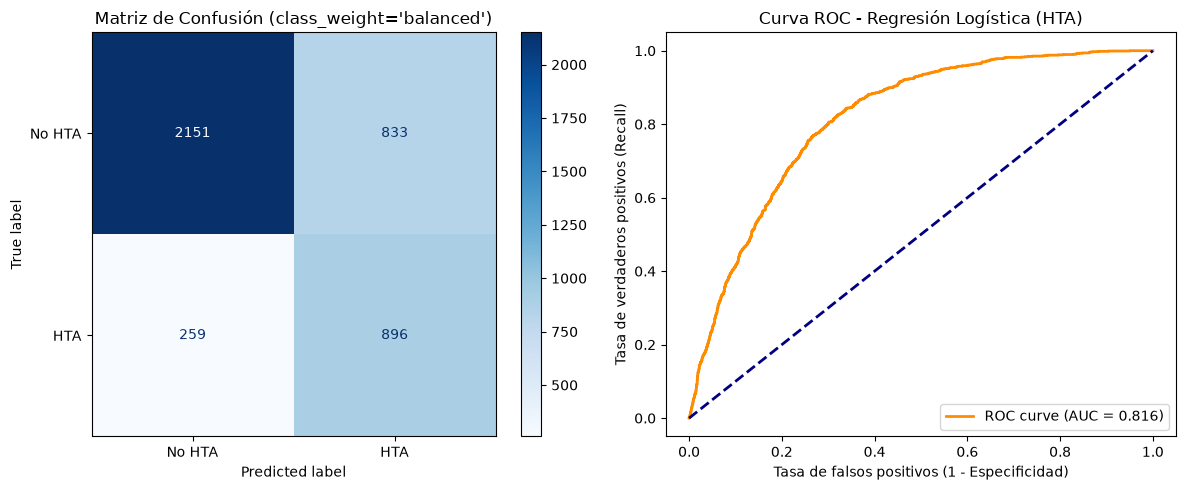

In [4]:
# ======================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS 
# ======================================================

# Predicciones 
y_pred_hta = reg_log_hta_class_weight.predict(X_test_hta)
y_pred_proba_hta = reg_log_hta_class_weight.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)")
print(classification_report(y_test_hta, y_pred_hta, digits=4))

auc_hta = roc_auc_score(y_test_hta, y_pred_proba_hta)
print(f"ROC-AUC Score: {auc_hta:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_hta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (class_weight='balanced')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_hta, y_pred_proba_hta)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_hta_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [5]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, reg_log_hta_class_weight.predict(X_train_hta))
recall_test = recall_score(y_test_hta, reg_log_hta_class_weight.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.7816 | Recall test: 0.7758
Diferencia: 0.0058


INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado + Factor Adulto)
              precision    recall  f1-score   support

           0     0.9123    0.6585    0.7649      2984
           1     0.4866    0.8364    0.6153      1155

    accuracy                         0.7081      4139
   macro avg     0.6995    0.7474    0.6901      4139
weighted avg     0.7935    0.7081    0.7231      4139

ROC-AUC Score: 0.8139


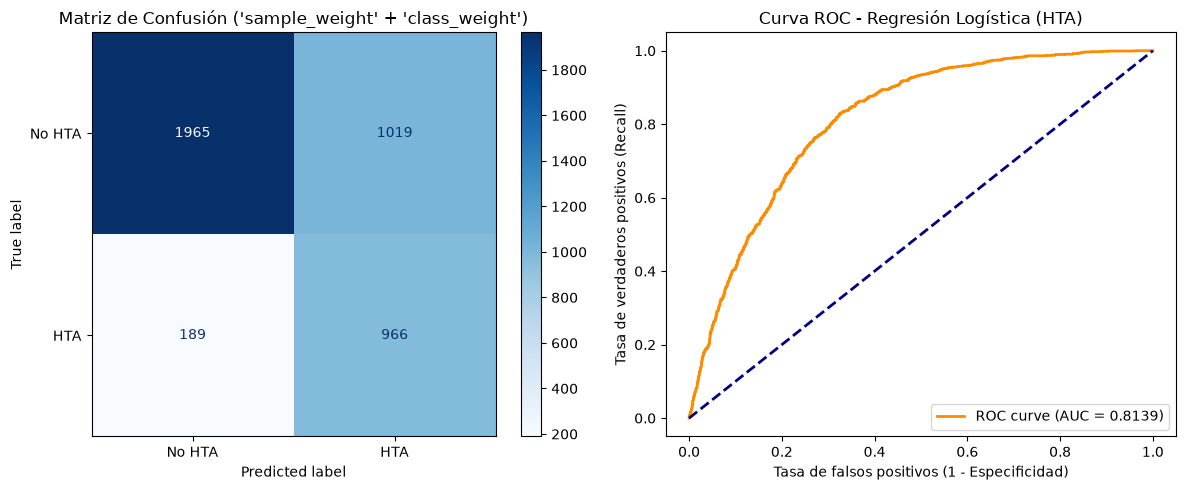

In [6]:
# =======================================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS Y FACTOR ADULTO
# =======================================================================

# Predicciones 
y_pred_hta = reg_log_hta.predict(X_test_hta)
y_pred_proba_hta = reg_log_hta.predict_proba(X_test_hta)[:, 1]

# Evaluación de métricas
print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado + Factor Adulto)")
print(classification_report(y_test_hta, y_pred_hta, digits=4))

auc_hta = roc_auc_score(y_test_hta, y_pred_proba_hta)
print(f"ROC-AUC Score: {auc_hta:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_hta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión ('sample_weight' + 'class_weight')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_hta, y_pred_proba_hta)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [7]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, reg_log_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, reg_log_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8376 | Recall test: 0.8364
Diferencia: 0.0013


In [8]:
# 1. Obtenemos las probabilidades predichas (ya entrenado con 'balanced' + sample_weight)
y_proba_hta = reg_log_hta.predict_proba(X_test_hta)[:, 1]

# 2. Probamos distintos umbrales (ejemplo: 0.40, 0.45, 0.50, 0.55)
umbrales = [0.35, 0.40, 0.45, 0.50, 0.55]

for u in umbrales:
    y_pred_u = (y_proba_hta >= u).astype(int)
    report = classification_report(
        y_test_hta, y_pred_u, digits=4, output_dict=True
    )

    rec = report["1"]["recall"]
    prec = report["1"]["precision"]
    f1 = report["1"]["f1-score"]
    acc = report["accuracy"]

    print(f"Umbral {u:.2f} -> Recall HTA: {rec*100:.2f}% | Precisión HTA: {prec*100:.2f}% | F1: {f1:.2f}% | Accuracy Global: {acc*100:.2f}")

Umbral 0.35 -> Recall HTA: 92.73% | Precisión HTA: 42.75% | F1: 0.59% | Accuracy Global: 63.32
Umbral 0.40 -> Recall HTA: 89.78% | Precisión HTA: 44.45% | F1: 0.59% | Accuracy Global: 65.84
Umbral 0.45 -> Recall HTA: 87.36% | Precisión HTA: 46.54% | F1: 0.61% | Accuracy Global: 68.47
Umbral 0.50 -> Recall HTA: 83.64% | Precisión HTA: 48.66% | F1: 0.62% | Accuracy Global: 70.81
Umbral 0.55 -> Recall HTA: 78.96% | Precisión HTA: 50.67% | F1: 0.62% | Accuracy Global: 72.67


HIPERTENSIÓN CON SMOTE
              precision    recall  f1-score   support

           0     0.8873    0.7282    0.7999      2984
           1     0.5201    0.7610    0.6179      1155

    accuracy                         0.7374      4139
   macro avg     0.7037    0.7446    0.7089      4139
weighted avg     0.7848    0.7374    0.7491      4139

ROC-AUC Score: 0.8150


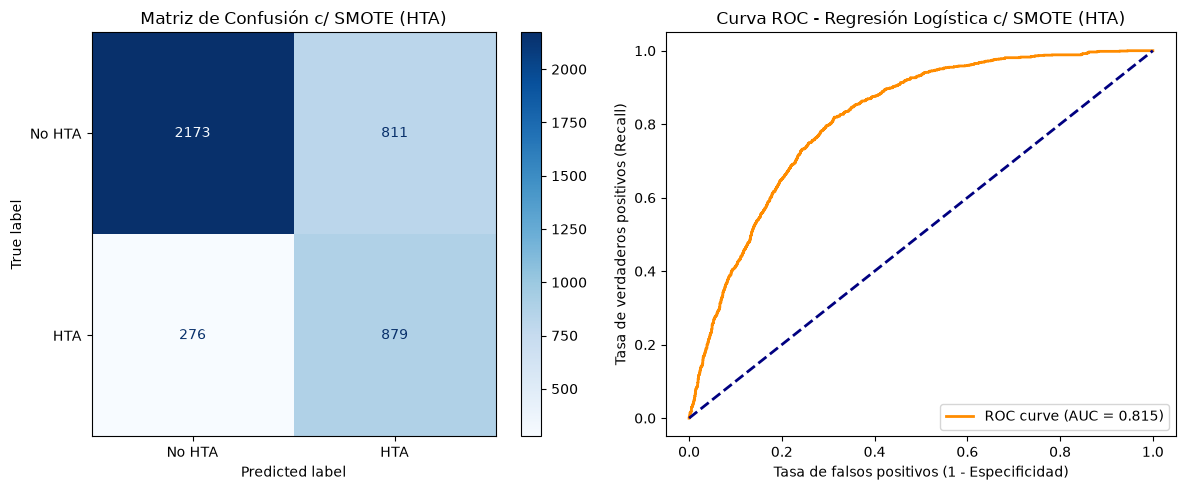

In [9]:
# ==========================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON SMOTE
# ==========================================

# Se evalua en el X_test original 
y_pred_smote = reg_log_hta_smote.predict(X_test_hta)
y_proba_smote = reg_log_hta_smote.predict_proba(X_test_hta)[:, 1]

print("HIPERTENSIÓN CON SMOTE")
print(classification_report(y_test_hta, y_pred_smote, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test_hta, y_proba_smote):.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión c/ SMOTE (HTA)")

# Curva ROC
fpr_smote, tpr_smote, _ = roc_curve(y_test_hta, y_proba_smote)
auc_smote = roc_auc_score(y_test_hta, y_proba_smote)
axes[1].plot(fpr_smote, tpr_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_smote:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística c/ SMOTE (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/reg_log_hta_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, reg_log_hta_smote.predict(X_train_hta))
recall_test = recall_score(y_test_hta, reg_log_hta_smote.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.7738 | Recall test: 0.7610
Diferencia: 0.0127


### CONCLUSIONES METODOLÓGICAS 

- El modelo seleccionado como Baseline es la combinación de class_weight='balanced' + sample_weight (FACTORADULTO), el cual es la opción más robusta clínicamente. Este modelo logra reducir los Falsos Negativos a solo 159 casos, mientras que el modelo que solo usa class_weight este número aumenta a 223 y 238 para el modelo con SMOTE. 

- SMOTE vs. FACTORADULTO: SMOTE incrementa ligeramente la Esepcificidad y la precision, pero al no incluir el factor de elevación de la encuesta nacional, se pierde la capacidad de detección de enfermos (Recall cae a 79,39%)

- Por ultimo, el análisis de umbrales demuestra que la mejor opción sigue siendo class_weight="balanced", o sea, 0.50

# EVALUACIÓN RANDOM FOREST

In [11]:
# Cargar modelo Random Forest
import joblib 
rf_hta_class_weight = joblib.load("../models/random_forest_hta_class_weight.joblib")
rf_hta = joblib.load("../models/random_forest_hta.joblib")
rf_smote_hta = joblib.load("../models/rf_smote_hta.joblib")
rf_subsample_hta = joblib.load("../models/subsample_random_forest_hta.joblib")
brf_hta = joblib.load("../models/balanced_random_forest_hta.joblib")
brf_hta_sample_weight = joblib.load("../models/brf_hta_sample_weight.joblib")
brf_opt_gridsearch = joblib.load("../models/brf_hta_opt_gridsearch.joblib")

INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA)
              precision    recall  f1-score   support

           0     0.8553    0.7983    0.8258      2984
           1     0.5554    0.6511    0.5994      1155

    accuracy                         0.7572      4139
   macro avg     0.7053    0.7247    0.7126      4139
weighted avg     0.7716    0.7572    0.7626      4139

ROC-AUC Score: 0.8131


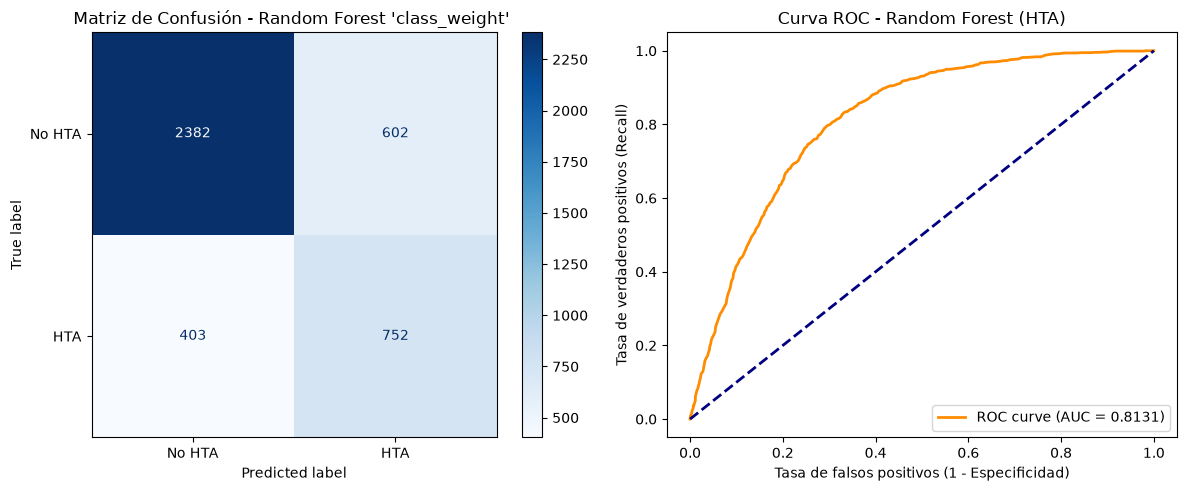

In [12]:
# ========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') - HIPERTENSIÓN
# ========================================================

# Predicciones 
y_pred_rf_hta_class_weight = rf_hta_class_weight.predict(X_test_hta)
y_proba_rf_hta_class_weight = rf_hta_class_weight.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA)")
print(classification_report(y_test_hta, y_pred_rf_hta_class_weight, digits=4))

# ROC-AUC 
auc_rf_hta_class_weight = roc_auc_score(y_test_hta, y_proba_rf_hta_class_weight)
print(f"ROC-AUC Score: {auc_rf_hta_class_weight:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_hta_class_weight = confusion_matrix(y_test_hta, y_pred_rf_hta_class_weight)
disp_rf_hta_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_hta_class_weight, display_labels=["No HTA", "HTA"])
disp_rf_hta_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest 'class_weight' ")

# Curva ROC
fpr_rf_hta_class_weight, tpr_rf_hta_class_weight, _ = roc_curve(y_test_hta, y_proba_rf_hta_class_weight)
axes[1].plot(fpr_rf_hta_class_weight, tpr_rf_hta_class_weight, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_hta_class_weight:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/rf_hta_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [13]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, rf_hta_class_weight.predict(X_train_hta))
recall_test = recall_score(y_test_hta, rf_hta_class_weight.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.6511
Diferencia: 0.3489


INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA) FACTOR ADULTO / BALANCEADO
              precision    recall  f1-score   support

           0     0.8673    0.7735    0.8177      2984
           1     0.5426    0.6944    0.6092      1155

    accuracy                         0.7514      4139
   macro avg     0.7050    0.7339    0.7135      4139
weighted avg     0.7767    0.7514    0.7595      4139

ROC-AUC Score: 0.8128


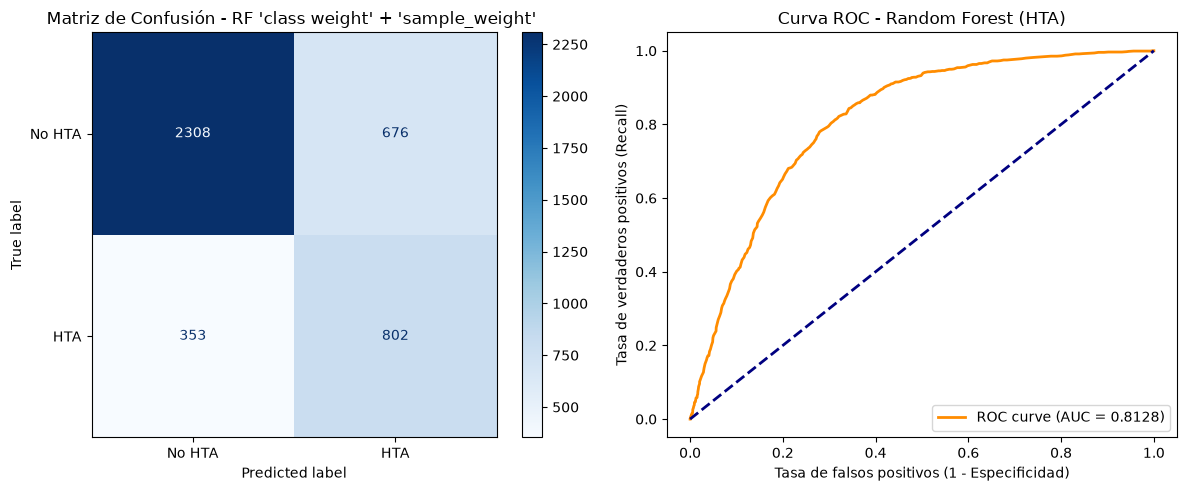

In [14]:
# ========================================================================
# EVALUACIÓN RANDOM FOREST ('class_weight' + FACTORADULTO) - HIPERTENSIÓN
# ========================================================================

# Predicciones 
y_pred_rf_hta = rf_hta.predict(X_test_hta)
y_proba_rf_hta = rf_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA) FACTOR ADULTO / BALANCEADO")
print(classification_report(y_test_hta, y_pred_rf_hta, digits=4))

# ROC-AUC 
auc_rf_hta = roc_auc_score(y_test_hta, y_proba_rf_hta)
print(f"ROC-AUC Score: {auc_rf_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_hta = confusion_matrix(y_test_hta, y_pred_rf_hta)
disp_rf_hta = ConfusionMatrixDisplay(confusion_matrix=cm_rf_hta.astype(int), display_labels=["No HTA", "HTA"])
disp_rf_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF 'class weight' + 'sample_weight' ")

# Curva ROC
fpr_rf_hta, tpr_rf_hta, _ = roc_curve(y_test_hta, y_proba_rf_hta)
axes[1].plot(fpr_rf_hta, tpr_rf_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/rf_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, rf_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, rf_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9905 | Recall test: 0.6944
Diferencia: 0.2961


INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE
              precision    recall  f1-score   support

           0     0.8063    0.8874    0.8449      2984
           1     0.6070    0.4494    0.5164      1155

    accuracy                         0.7652      4139
   macro avg     0.7067    0.6684    0.6807      4139
weighted avg     0.7507    0.7652    0.7533      4139

ROC-AUC Score: 0.8146


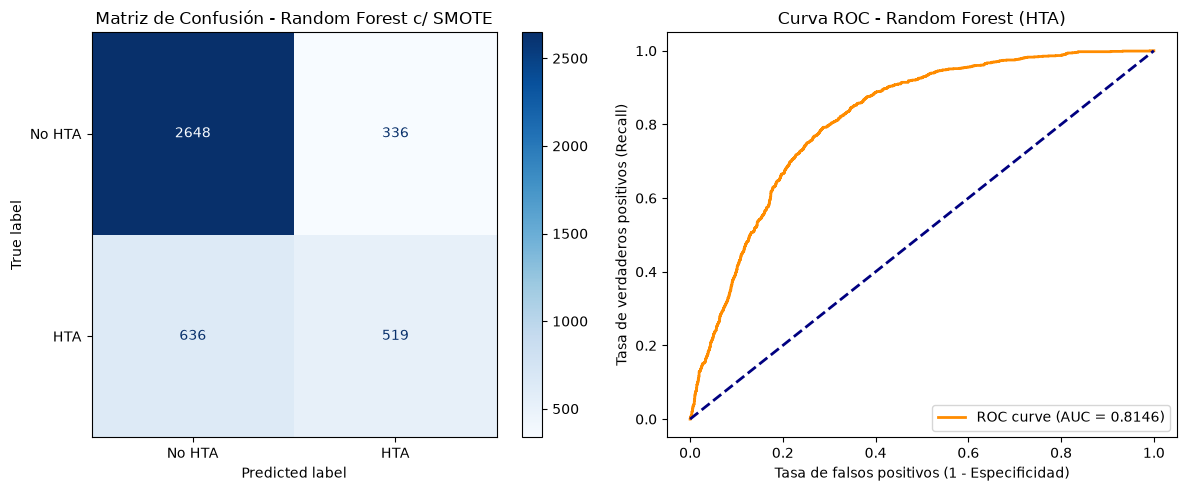

In [16]:
# ===============================
# EVALUACIÓN RANDOM FOREST SMOTE 
# ===============================

# Predicciones 
y_pred_rf_smote_hta = rf_smote_hta.predict(X_test_hta)
y_proba_rf_smote_hta = rf_smote_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE")
print(classification_report(y_test_hta, y_pred_rf_smote_hta, digits=4))

# ROC-AUC 
auc_rf_smote_hta = roc_auc_score(y_test_hta, y_proba_rf_smote_hta)
print(f"ROC-AUC Score: {auc_rf_smote_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_smote_hta = confusion_matrix(y_test_hta, y_pred_rf_smote_hta)
disp_rf_smote_hta = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote_hta, display_labels=["No HTA", "HTA"])
disp_rf_smote_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest c/ SMOTE")

# Curva ROC
fpr_rf_smote_hta, tpr_rf_smote_hta, _ = roc_curve(y_test_hta, y_proba_rf_smote_hta)
axes[1].plot(fpr_rf_smote_hta, tpr_rf_smote_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_smote_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_hta_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, rf_smote_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, rf_smote_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.5471 | Recall test: 0.4494
Diferencia: 0.0977


INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS
              precision    recall  f1-score   support

           0     0.8902    0.7306    0.8025      2984
           1     0.5243    0.7671    0.6228      1155

    accuracy                         0.7408      4139
   macro avg     0.7072    0.7488    0.7127      4139
weighted avg     0.7881    0.7408    0.7524      4139

ROC-AUC Score: 0.8143


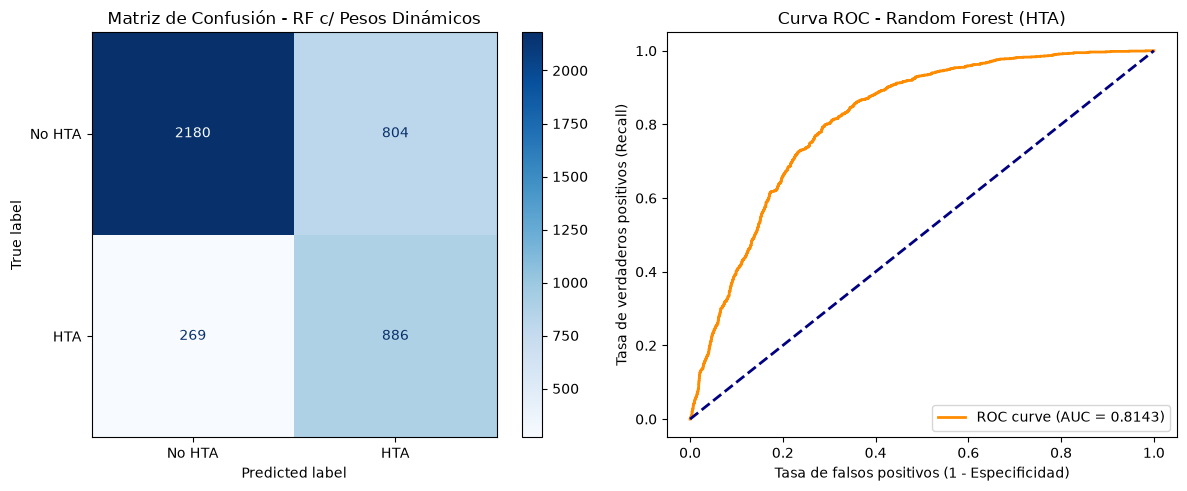

In [18]:
# ===========================================
# EVALUACIÓN RANDOM FOREST C/ PESOS DINÁMICOS
# ===========================================

# Predicciones 
y_pred_rf_subsample = rf_subsample_hta.predict(X_test_hta)
y_proba_rf_subsample = rf_subsample_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS")
print(classification_report(y_test_hta, y_pred_rf_subsample, digits=4))

# ROC-AUC 
auc_rf_subsample = roc_auc_score(y_test_hta, y_proba_rf_subsample)
print(f"ROC-AUC Score: {auc_rf_subsample:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_subsample = confusion_matrix(y_test_hta, y_pred_rf_subsample)
disp_rf_subsample = ConfusionMatrixDisplay(confusion_matrix=cm_rf_subsample, display_labels=["No HTA", "HTA"])
disp_rf_subsample.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF c/ Pesos Dinámicos")

# Curva ROC
fpr_rf_subsample, tpr_rf_subsample, _ = roc_curve(y_test_hta, y_proba_rf_subsample)
axes[1].plot(fpr_rf_subsample, tpr_rf_subsample, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_subsample:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/rf_hta_pesos_dinamicos.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, rf_subsample_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, rf_subsample_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8586 | Recall test: 0.7671
Diferencia: 0.0915


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (HTA)
              precision    recall  f1-score   support

           0     0.8763    0.7597    0.8139      2984
           1     0.5380    0.7229    0.6169      1155

    accuracy                         0.7495      4139
   macro avg     0.7072    0.7413    0.7154      4139
weighted avg     0.7819    0.7495    0.7589      4139

ROC-AUC Score: 0.8161


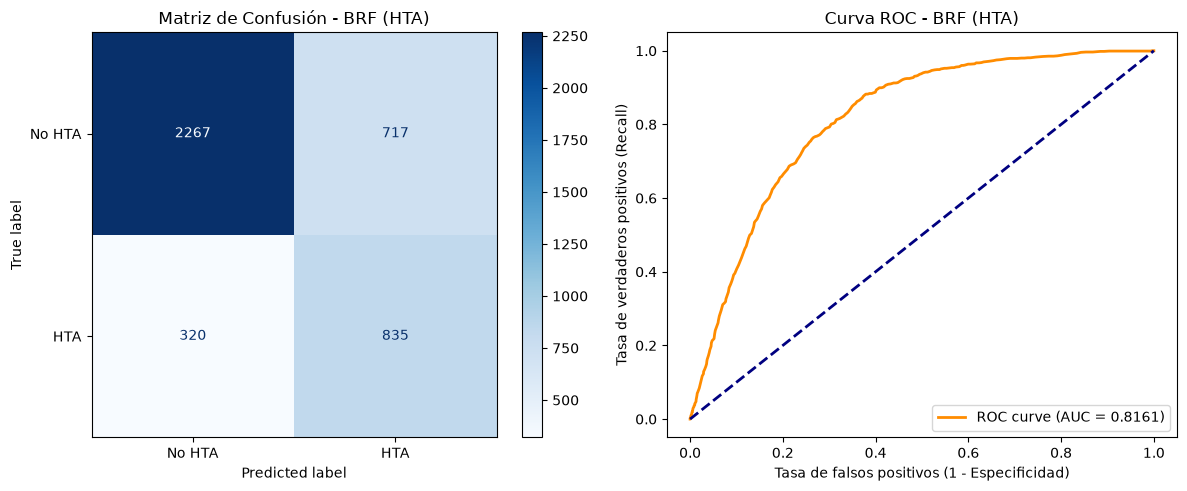

In [20]:
# ====================================
# EVALUACIÓN  BALANCED RANDOM FOREST 
# ====================================

# Predicciones 
y_pred_brf_hta = brf_hta.predict(X_test_hta)
y_proba_brf_hta = brf_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (HTA)")
print(classification_report(y_test_hta, y_pred_brf_hta, digits=4))

# ROC-AUC 
auc_brf_hta = roc_auc_score(y_test_hta, y_proba_brf_hta)
print(f"ROC-AUC Score: {auc_brf_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_hta = confusion_matrix(y_test_hta, y_pred_brf_hta)
disp_brf_hta = ConfusionMatrixDisplay(confusion_matrix=cm_brf_hta, display_labels=["No HTA", "HTA"])
disp_brf_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF (HTA)")

# Curva ROC
fpr_brf_hta, tpr_brf_hta, _ = roc_curve(y_test_hta, y_proba_brf_hta)
axes[1].plot(fpr_brf_hta, tpr_brf_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_brf_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, brf_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, brf_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 1.0000 | Recall test: 0.7229
Diferencia: 0.2771


,Umbral,Recall HTA,Precisión HTA,F1-Score,FN (Enfermos No Detectados),FP (Sanos Clasificados como Enfermos)
0,0.20,97.75%,35.89%,0.5250,26,2017
1,0.25,95.93%,38.23%,0.5468,47,1790
2,0.30,94.37%,40.66%,0.5683,65,1591
3,0.35,92.90%,42.58%,0.5839,82,1447
4,0.40,90.82%,44.94%,0.6013,106,1285
5,0.45,87.19%,46.99%,0.6107,148,1136
6,0.50,82.60%,49.71%,0.6207,201,965


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST FACTORADULTO
              precision    recall  f1-score   support

           0     0.9095    0.6766    0.7759      2984
           1     0.4971    0.8260    0.6207      1155

    accuracy                         0.7183      4139
   macro avg     0.7033    0.7513    0.6983      4139
weighted avg     0.7944    0.7183    0.7326      4139

ROC-AUC Score: 0.8150


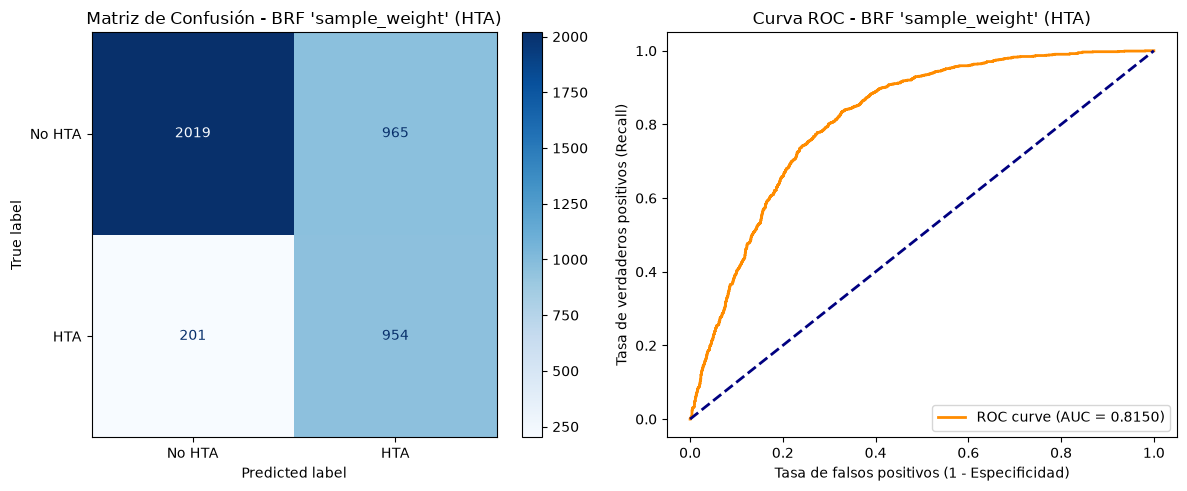

In [22]:
# =============================================
# EVALUACIÓN Balanced Random Forest 'sample_weight'
# =============================================

# Predicciones 
y_pred_hta_sample_weight = brf_hta_sample_weight.predict(X_test_hta)
y_proba_hta_sample_weight = brf_hta_sample_weight.predict_proba(X_test_hta)[:, 1]

# 5. Barrido de Umbrales
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
resultados = []

for u in umbrales:
    y_pred_u = (y_proba_hta_sample_weight >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_hta, y_pred_u).ravel()
    rep = classification_report(y_test_hta, y_pred_u, output_dict=True)

    resultados.append(
        {
            "Umbral": u,
            "Recall HTA": f"{rep['1']['recall']*100:.2f}%",
            "Precisión HTA": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos No Detectados)": int(fn),
            "FP (Sanos Clasificados como Enfermos)": int(fp)
        }
    )

df_umbrales = pd.DataFrame(resultados)
display(df_umbrales)

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST FACTORADULTO")
print(classification_report(y_test_hta, y_pred_hta_sample_weight, digits=4))

# ROC-AUC 
auc_hta_sample_weight = roc_auc_score(y_test_hta, y_proba_hta_sample_weight)
print(f"ROC-AUC Score: {auc_hta_sample_weight:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_hta_sample_weight = confusion_matrix(y_test_hta, y_pred_hta_sample_weight)
disp_hta_sample_weight = ConfusionMatrixDisplay(confusion_matrix=cm_hta_sample_weight, display_labels=["No HTA", "HTA"])
disp_hta_sample_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF 'sample_weight' (HTA)")

# Curva ROC
fpr_hta_sample_weight, tpr_hta_sample_weight, _ = roc_curve(y_test_hta, y_proba_hta_sample_weight)
axes[1].plot(fpr_hta_sample_weight, tpr_hta_sample_weight, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta_sample_weight:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF 'sample_weight' (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/brf_hta_sample_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [23]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, brf_hta_sample_weight.predict(X_train_hta))
recall_test = recall_score(y_test_hta, brf_hta_sample_weight.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.9004 | Recall test: 0.8260
Diferencia: 0.0744


In [24]:
import numpy as np
from sklearn.metrics import roc_curve

# Calcular el umbral exacto según el Índice de Youden
fpr, tpr, thresholds = roc_curve(
    y_test_hta, brf_hta_sample_weight.predict_proba(X_test_hta)[:, 1]
)
umbral_exacto = thresholds[np.argmax(tpr - fpr)]

print(f"Umbral exacto de Youden: {umbral_exacto:.2f}")

Umbral exacto de Youden: 0.50


,Umbral,Recall HTA,Precisión HTA,F1-Score,FN (Enfermos No Detectados),FP (Sanos Clasificados como Enfermos)
0,0.20,98.18%,34.31%,0.5085,21,2171
1,0.25,96.19%,36.93%,0.5337,44,1897
2,0.30,94.89%,39.45%,0.5573,59,1682
3,0.35,92.64%,41.70%,0.5751,85,1496
4,0.40,90.22%,43.98%,0.5914,113,1327
5,0.45,87.27%,46.13%,0.6036,147,1177
6,0.50,81.99%,48.10%,0.6063,208,1022
7,0.60,70.65%,52.51%,0.6024,339,738


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST OPTIMIZADO
              precision    recall  f1-score   support

           0     0.9041    0.6575    0.7614      2984
           1     0.4810    0.8199    0.6063      1155

    accuracy                         0.7028      4139
   macro avg     0.6926    0.7387    0.6838      4139
weighted avg     0.7861    0.7028    0.7181      4139

ROC-AUC Score: 0.8064


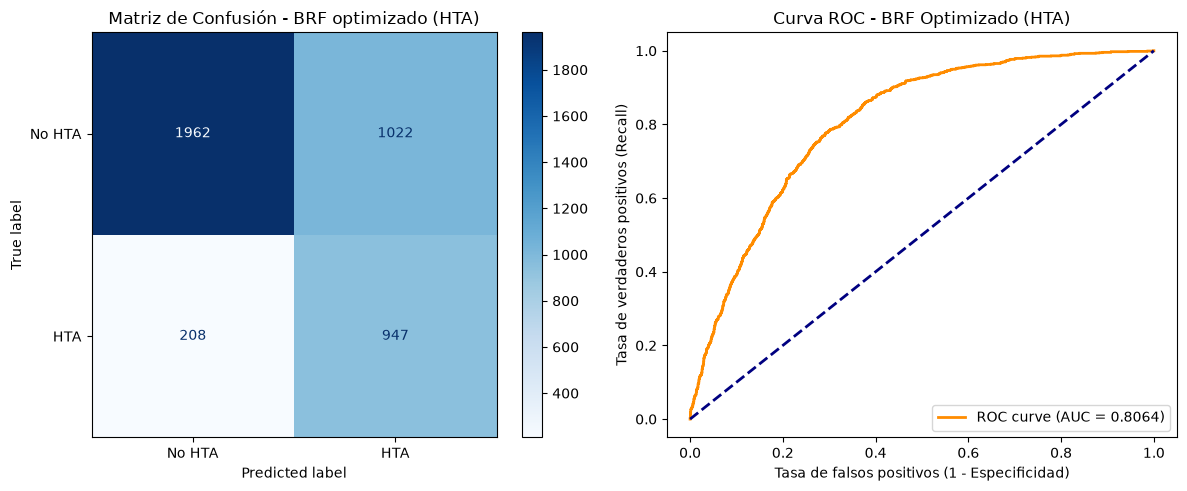

In [25]:

# ========================================================
# EVALUACIÓN Balanced Random Forest optimizado GridSearch
# ========================================================

# Predicciones 
y_pred_opt_gridsearch = brf_opt_gridsearch.predict(X_test_hta)
y_proba_opt_gridsearch = brf_opt_gridsearch.predict_proba(X_test_hta)[:, 1]

# 5. Barrido de Umbrales
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]
resultados = []

for u in umbrales:
    y_pred_u = (y_proba_opt_gridsearch >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_hta, y_pred_u).ravel()
    rep = classification_report(y_test_hta, y_pred_u, output_dict=True)

    resultados.append(
        {
            "Umbral": u,
            "Recall HTA": f"{rep['1']['recall']*100:.2f}%",
            "Precisión HTA": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos No Detectados)": int(fn),
            "FP (Sanos Clasificados como Enfermos)": int(fp)
        }
    )

df_umbrales = pd.DataFrame(resultados)
display(df_umbrales)

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST OPTIMIZADO")
print(classification_report(y_test_hta, y_pred_opt_gridsearch, digits=4))

# ROC-AUC 
auc_opt_hta_gridsearch = roc_auc_score(y_test_hta, y_proba_opt_gridsearch)
print(f"ROC-AUC Score: {auc_opt_hta_gridsearch:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_opt_hta_gridsearch = confusion_matrix(y_test_hta, y_pred_opt_gridsearch)
disp_opt_hta_gridsearch = ConfusionMatrixDisplay(confusion_matrix=cm_opt_hta_gridsearch, display_labels=["No HTA", "HTA"])
disp_opt_hta_gridsearch.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF optimizado (HTA)")

# Curva ROC
fpr_opt_hta_gridsearch, tpr_opt_hta_gridsearch, _ = roc_curve(y_test_hta, y_proba_opt_gridsearch)
axes[1].plot(fpr_opt_hta_gridsearch, tpr_opt_hta_gridsearch, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_opt_hta_gridsearch:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - BRF Optimizado (HTA)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/rf_hta_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [26]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, brf_opt_gridsearch.predict(X_train_hta))
recall_test = recall_score(y_test_hta, brf_opt_gridsearch.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8179 | Recall test: 0.8199
Diferencia: 0.0020


In [27]:
import numpy as np
from sklearn.metrics import roc_curve

# Calcular el umbral exacto según el Índice de Youden
fpr, tpr, thresholds = roc_curve(
    y_test_hta, brf_opt_gridsearch.predict_proba(X_test_hta)[:, 1]
)
umbral_exacto = thresholds[np.argmax(tpr - fpr)]

print(f"Umbral exacto de Youden: {umbral_exacto:.2f}")

Umbral exacto de Youden: 0.55


# SVM

In [28]:
# Cargar datos 
svm_hta_cw = joblib.load("../models/svm_hta_cw.joblib")
svm_hta = joblib.load("../models/svm_hta.joblib")
svm_hta_smote = joblib.load("../models/svm_hta_smote")
svm_hta_opt = joblib.load("../models/svm_hta_optimizado.joblib")

INFORME DE CLASIFICACIÓN - SVM (HTA)
              precision    recall  f1-score   support

           0     0.8969    0.6971    0.7845      2984
           1     0.5033    0.7931    0.6158      1155

    accuracy                         0.7238      4139
   macro avg     0.7001    0.7451    0.7001      4139
weighted avg     0.7871    0.7238    0.7374      4139

ROC-AUC Score: 0.8063


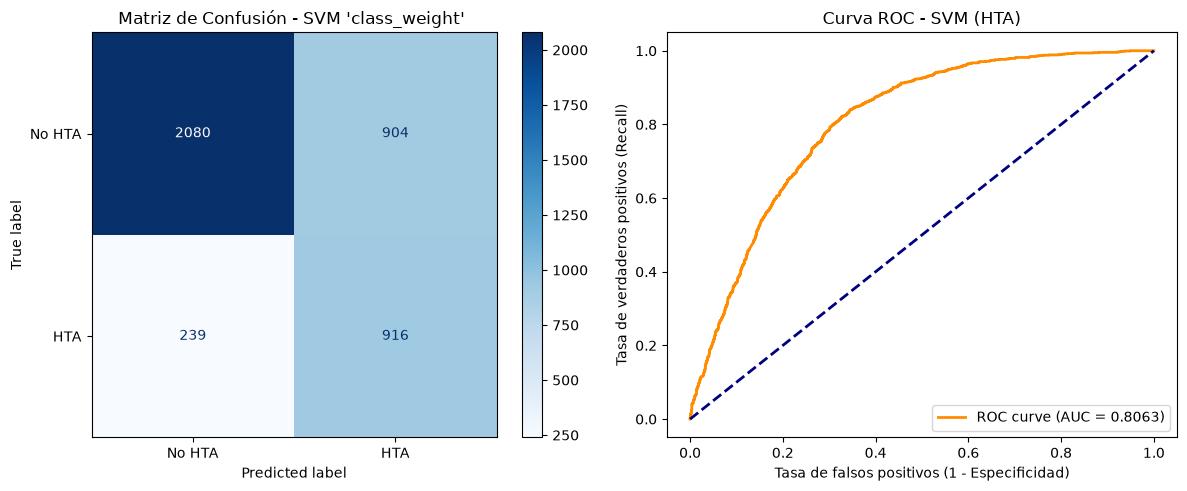

In [29]:
# ==============================================
# EVALUACIÓN SVM 'class_weight' - HIPERTENSIÓN
# ==============================================

# Predicciones 
y_pred_svm_hta_cw = svm_hta_cw.predict(X_test_hta)
y_pred_proba_svm_hta_cw = svm_hta_cw.predict_proba(X_test_hta)[:, 1]



print("INFORME DE CLASIFICACIÓN - SVM (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta_cw, digits=4))

# ROC-AUC
auc_svm_hta_cw = roc_auc_score(y_test_hta, y_pred_proba_svm_hta_cw)
print(f"ROC-AUC Score: {auc_svm_hta_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta_cw = confusion_matrix(y_test_hta,y_pred_svm_hta_cw)
disp_svm_hta_cw = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta_cw, display_labels=["No HTA", "HTA"])
disp_svm_hta_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM 'class_weight' ")

# CURVA ROC 
fpr_svm_hta_cw, tpr_svm_hta_cw, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta_cw)
axes[1].plot(fpr_svm_hta_cw, tpr_svm_hta_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta_cw:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_hta_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [30]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, svm_hta_cw.predict(X_train_hta))
recall_test = recall_score(y_test_hta, svm_hta_cw.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8989 | Recall test: 0.7931
Diferencia: 0.1058


INFORME DE CLASIFICACIÓN - SVM (HTA)
              precision    recall  f1-score   support

           0     0.8818    0.7148    0.7896      2984
           1     0.5052    0.7524    0.6045      1155

    accuracy                         0.7253      4139
   macro avg     0.6935    0.7336    0.6970      4139
weighted avg     0.7767    0.7253    0.7379      4139

ROC-AUC Score: 0.8029


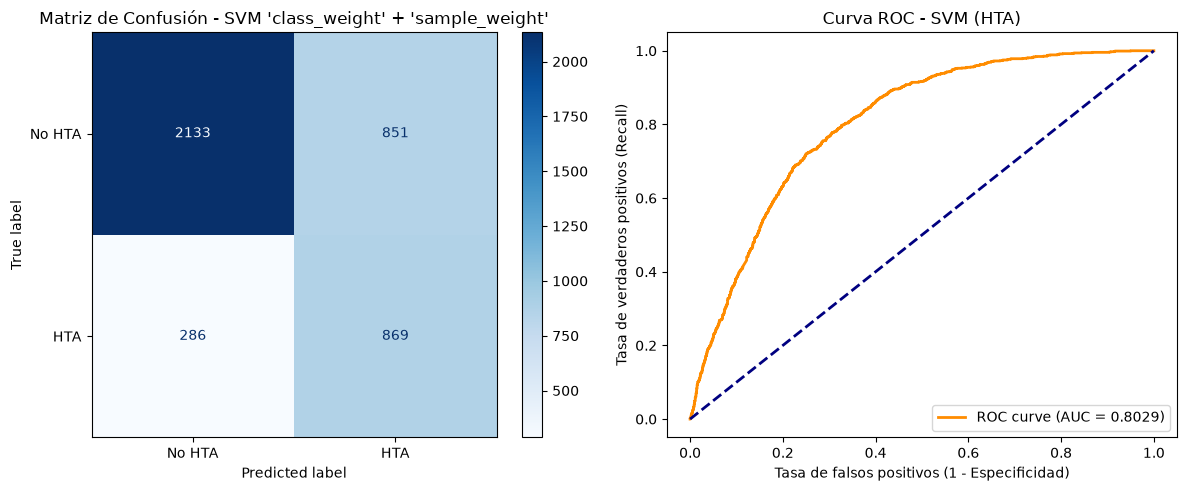

In [31]:
# ===============================================================
# EVALUACIÓN SVM 'class_weight' + 'sample_weight' - HIPERTENSIÓN
# ===============================================================

# Predicciones 
y_pred_svm_hta = svm_hta.predict(X_test_hta)
y_pred_proba_svm_hta = svm_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - SVM (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta, digits=4))

# ROC-AUC
auc_svm_hta = roc_auc_score(y_test_hta, y_pred_proba_svm_hta)
print(f"ROC-AUC Score: {auc_svm_hta:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta = confusion_matrix(y_test_hta,y_pred_svm_hta)
disp_svm_hta = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta, display_labels=["No HTA", "HTA"])
disp_svm_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM 'class_weight' + 'sample_weight'")

# CURVA ROC 
fpr_svm_hta, tpr_svm_hta, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta)
axes[1].plot(fpr_svm_hta, tpr_svm_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [32]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, svm_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, svm_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8740 | Recall test: 0.7524
Diferencia: 0.1216


INFORME DE CLASIFICACIÓN - SVM CON SMOTE (HTA)
              precision    recall  f1-score   support

           0     0.8233    0.8559    0.8393      2984
           1     0.5853    0.5255    0.5538      1155

    accuracy                         0.7637      4139
   macro avg     0.7043    0.6907    0.6966      4139
weighted avg     0.7569    0.7637    0.7596      4139

ROC-AUC Score: 0.8000


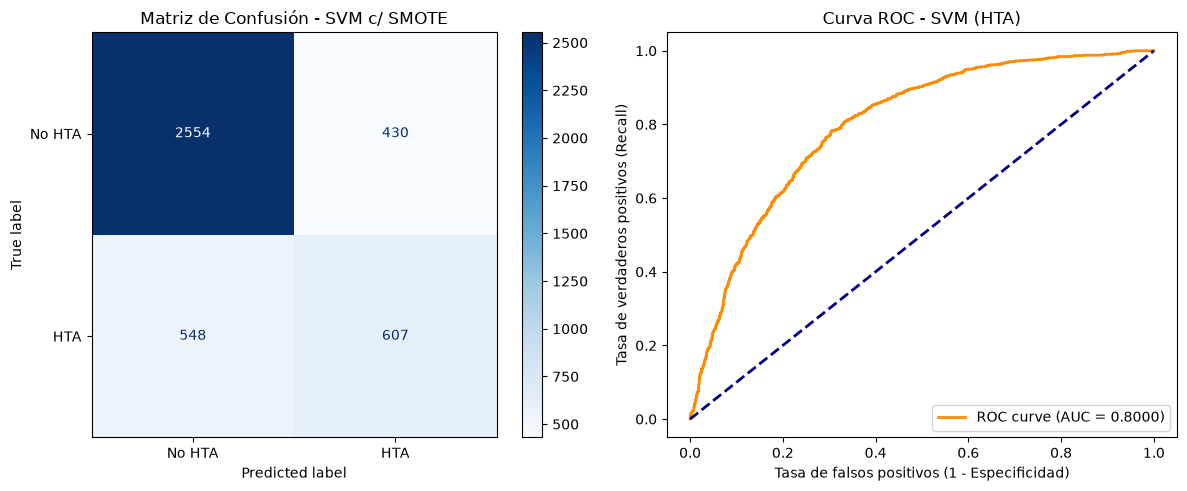

In [33]:
# ========================
# EVALUACIÓN SVM CON SMOTE
# ========================

# Predicciones 
y_pred_svm_hta_smote = svm_hta_smote.predict(X_test_hta)
y_pred_proba_svm_hta_smote = svm_hta_smote.predict_proba(X_test_hta)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM CON SMOTE (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta_smote, digits=4))

# ROC-AUC
auc_svm_hta_smote = roc_auc_score(y_test_hta, y_pred_proba_svm_hta_smote)
print(f"ROC-AUC Score: {auc_svm_hta_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta_smote = confusion_matrix(y_test_hta,y_pred_svm_hta_smote)
disp_svm_hta_smote = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta_smote, display_labels=["No HTA", "HTA"])
disp_svm_hta_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM c/ SMOTE")

# CURVA ROC 
fpr_svm_hta_smote, tpr_svm_hta_smote, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta_smote)
axes[1].plot(fpr_svm_hta_smote, tpr_svm_hta_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta_smote:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_hta_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, svm_hta_smote.predict(X_train_hta))
recall_test = recall_score(y_test_hta, svm_hta_smote.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.6781 | Recall test: 0.5255
Diferencia: 0.1525


INFORME DE CLASIFICACIÓN - SVM OPTIMIZADO(HTA)
              precision    recall  f1-score   support

           0     0.9026    0.6863    0.7797      2984
           1     0.4995    0.8087    0.6175      1155

    accuracy                         0.7205      4139
   macro avg     0.7010    0.7475    0.6986      4139
weighted avg     0.7901    0.7205    0.7345      4139

ROC-AUC Score: 0.8152


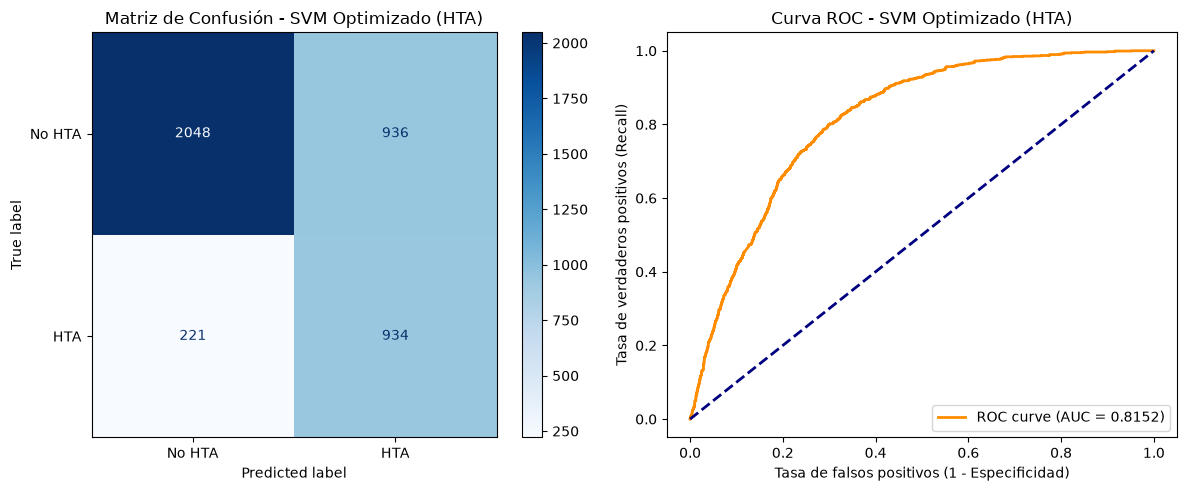

In [35]:
# ==============================================
# EVALUACIÓN SVM OPTIMIZADO - HIPERTENSIÓN
# ==============================================

# Predicciones 
y_pred_svm_hta_opt = svm_hta_opt.predict(X_test_hta)
y_pred_proba_svm_hta_opt = svm_hta_opt.predict_proba(X_test_hta)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM OPTIMIZADO(HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta_opt, digits=4))

# ROC-AUC
auc_svm_hta_opt = roc_auc_score(y_test_hta, y_pred_proba_svm_hta_opt)
print(f"ROC-AUC Score: {auc_svm_hta_opt:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta_opt = confusion_matrix(y_test_hta,y_pred_svm_hta_opt)
disp_svm_hta_opt = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta_opt, display_labels=["No HTA", "HTA"])
disp_svm_hta_opt.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM Optimizado (HTA)")

# CURVA ROC 
fpr_svm_hta_opt, tpr_svm_hta_opt, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta_opt)
axes[1].plot(fpr_svm_hta_opt, tpr_svm_hta_opt, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta_opt:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - SVM Optimizado (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/svm_hta_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [36]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, svm_hta_opt.predict(X_train_hta))
recall_test = recall_score(y_test_hta, svm_hta_opt.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8335 | Recall test: 0.8087
Diferencia: 0.0249


In [37]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

# Probabilidades predichas del SVM optimizado
y_pred_proba_svm_hta_opt = svm_hta_opt.predict_proba(X_test_hta)[:, 1]

# Rango extendido de umbrales
umbrales = [0.10, 0.15, 0.20, 0.25, 0.26, 0.30, 0.35, 0.40, 0.45, 0.50]
evaluacion_svm = []

for u in umbrales:
    y_pred_u = (y_pred_proba_svm_hta_opt >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_hta, y_pred_u).ravel()
    report = classification_report(y_test_hta, y_pred_u, output_dict=True)

    evaluacion_svm.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_svm = pd.DataFrame(evaluacion_svm)
display(df_umbrales_svm)

# Identificación matemática del umbral óptimo mediante el Índice de Youden
fpr, tpr, thresholds = roc_curve(y_test_hta, y_pred_proba_svm_hta_opt)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
youden_threshold = thresholds[opt_idx]

print("\n" + "=" * 50)
print(f"UMBRAL ÓPTIMO DE YOUDEN DETECTADO: {youden_threshold:.2f}") # PUNTO DE MÁXIMA UTILIDAD MÉDICA
print("=" * 50)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.10,0.9619,0.3912,0.5562,44,1729
1,0.15,0.9221,0.4298,0.5863,90,1413
2,0.20,0.8745,0.4635,0.6059,145,1169
3,0.25,0.8242,0.4945,0.6182,203,973
4,0.26,0.8095,0.4973,0.6161,220,945
5,0.30,0.7645,0.5216,0.6201,272,810
6,0.35,0.7100,0.5445,0.6163,335,686
7,0.40,0.6312,0.5656,0.5966,426,560
8,0.45,0.5481,0.5698,0.5587,522,478
9,0.50,0.4684,0.5900,0.5222,614,376



UMBRAL ÓPTIMO DE YOUDEN DETECTADO: 0.28


# EVALUACIÓN MODELOS XGBOOST

In [38]:
# CARGAR DATOS

import joblib

xgb_model_cw_hta = joblib.load("../models/xgb_model_cw_hta.joblib")
xgb_model_hta = joblib.load("../models/xgb_model_hta.joblib")
xgb_model_smote_hta = joblib.load("../models/xgb_model_smote_hta.joblib")
xgb_hta_opt = joblib.load("../models/xgb_hta_optimizado.joblib")

INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (HTA)
              precision    recall  f1-score   support

           0     0.8920    0.7084    0.7897      2984
           1     0.5082    0.7784    0.6149      1155

    accuracy                         0.7280      4139
   macro avg     0.7001    0.7434    0.7023      4139
weighted avg     0.7849    0.7280    0.7409      4139

ROC-AUC Score: 0.8121


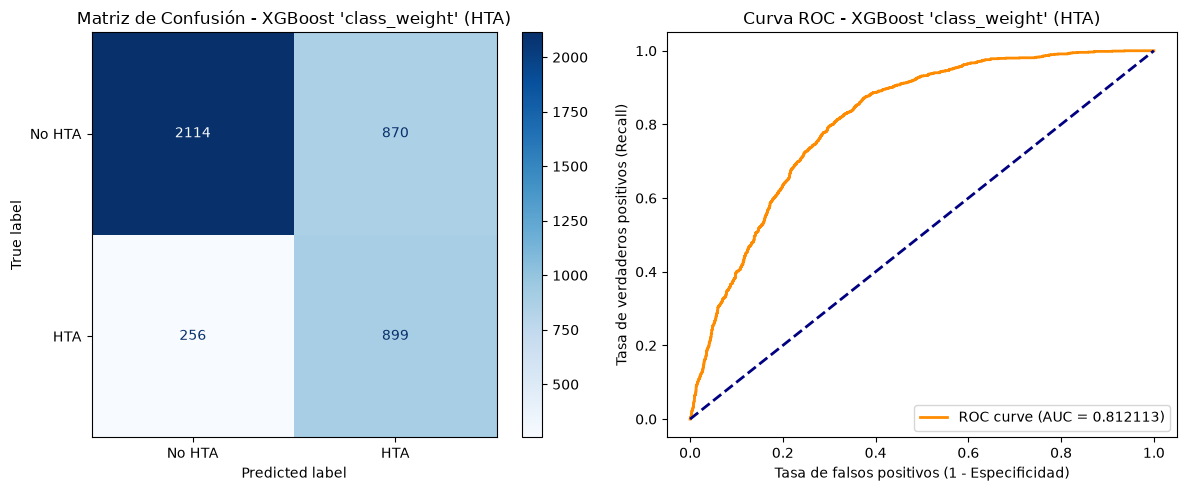

In [39]:
# ===============================================
# EVALUACIÓN XGBOOST 'class_weight' - HIPERTENSIÓN
# ===============================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_hta_cw = xgb_model_cw_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_hta_cw = xgb_model_cw_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_hta_cw, digits=4))

# ROC-AUC
auc_xgb_hta_cw = roc_auc_score(y_test_hta, y_pred_proba_xgb_hta_cw)
print(f"ROC-AUC Score: {auc_xgb_hta_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_hta_cw = confusion_matrix(y_test_hta, y_pred_xgb_hta_cw)
disp_xgb_hta_cw = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_hta_cw, display_labels=["No HTA", "HTA"])
disp_xgb_hta_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost 'class_weight' (HTA)")

# Curva ROC
fpr_xgb_hta_cw, tpr_xgb_hta_cw, _ = roc_curve(y_test_hta, y_pred_proba_xgb_hta_cw)
axes[1].plot(fpr_xgb_hta_cw, tpr_xgb_hta_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_hta_cw:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost 'class_weight' (HTA)")
axes[1].legend(loc="lower right")


plt.savefig("../reports/figures/results/xgb_hta_class_weight.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [40]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, xgb_model_cw_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, xgb_model_cw_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8805 | Recall test: 0.7784
Diferencia: 0.1021


INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)
              precision    recall  f1-score   support

           0     0.8847    0.7225    0.7954      2984
           1     0.5135    0.7567    0.6118      1155

    accuracy                         0.7321      4139
   macro avg     0.6991    0.7396    0.7036      4139
weighted avg     0.7811    0.7321    0.7442      4139

ROC-AUC Score: 0.8062


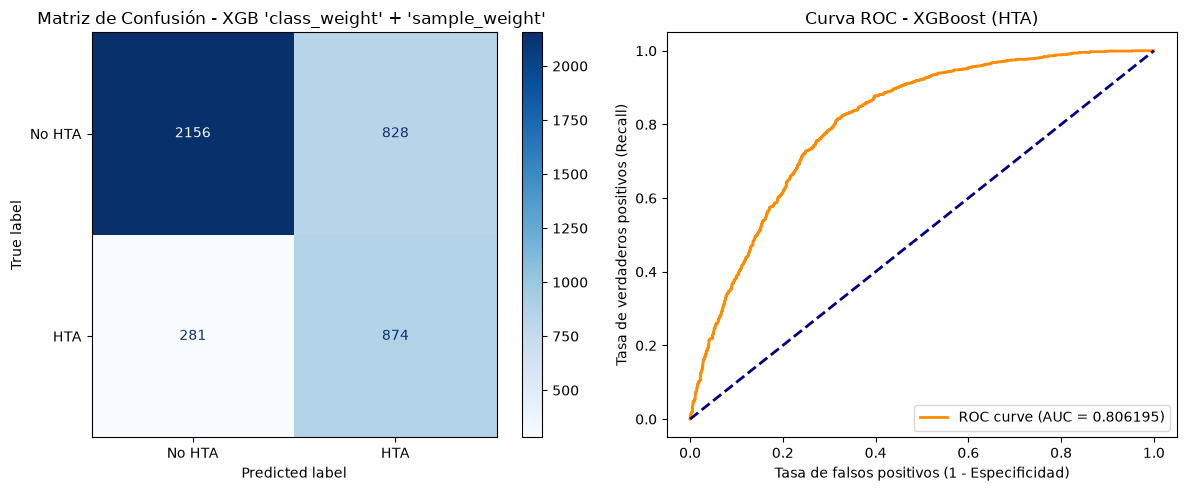

In [41]:
# ===========================================================
# EVALUACIÓN XGBOOST 'class_weight' y FACTORADULTO - HIPERTENSIÓN
# ===========================================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_hta = xgb_model_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_hta = xgb_model_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_hta, digits=4))

# ROC-AUC
auc_xgb_hta = roc_auc_score(y_test_hta, y_pred_proba_xgb_hta)
print(f"ROC-AUC Score: {auc_xgb_hta:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_hta = confusion_matrix(y_test_hta, y_pred_xgb_hta)
disp_xgb_hta = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_hta, display_labels=["No HTA", "HTA"])
disp_xgb_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGB 'class_weight' + 'sample_weight' ")

# Curva ROC
fpr_xgb_hta, tpr_xgb_hta, _ = roc_curve(y_test_hta, y_pred_proba_xgb_hta)
axes[1].plot(fpr_xgb_hta, tpr_xgb_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_hta:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_hta.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, xgb_model_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, xgb_model_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8649 | Recall test: 0.7567
Diferencia: 0.1082


INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (HTA)
              precision    recall  f1-score   support

           0     0.8278    0.8569    0.8421      2984
           1     0.5933    0.5394    0.5651      1155

    accuracy                         0.7683      4139
   macro avg     0.7106    0.6981    0.7036      4139
weighted avg     0.7624    0.7683    0.7648      4139

ROC-AUC Score: 0.8152


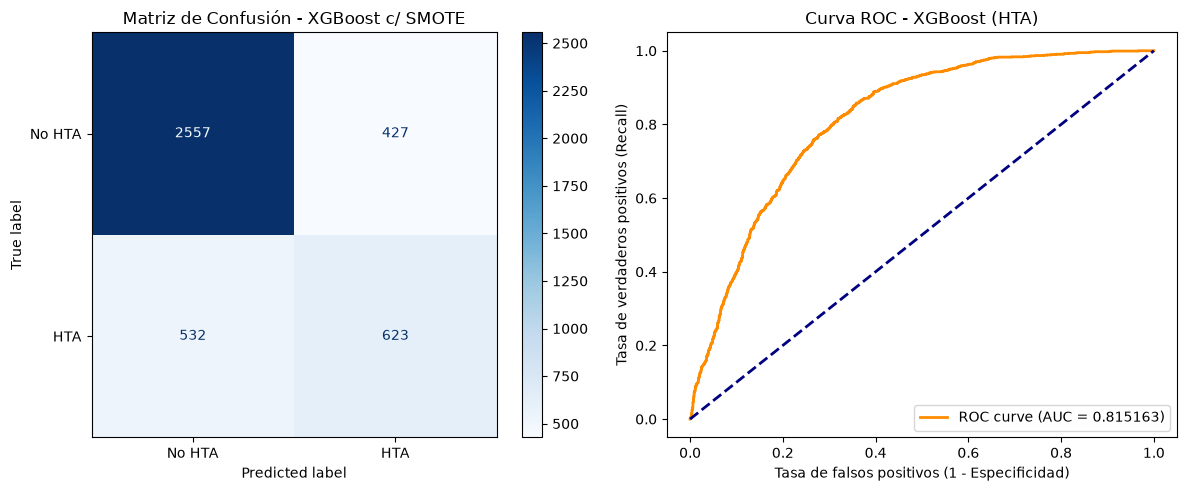

In [43]:
# ====================================
# EVALUACIÓN XGBOOST SMOTE - DIABETES
# ====================================


# Predicciones y probabilidades predichass
y_pred_proba_xgb_smote = xgb_model_smote_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_smote = xgb_model_smote_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_smote, digits=4))

# ROC-AUC
auc_xgb_smote = roc_auc_score(y_test_hta, y_pred_proba_xgb_smote)
print(f"ROC-AUC Score: {auc_xgb_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_smote = confusion_matrix(y_test_hta, y_pred_xgb_smote)
disp_xgb_smote = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_smote, display_labels=["No HTA", "HTA"])
disp_xgb_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost c/ SMOTE")

# Curva ROC
fpr_xgb_smote, tpr_xgb_smote, _ = roc_curve(y_test_hta, y_pred_proba_xgb_smote)
axes[1].plot(fpr_xgb_smote, tpr_xgb_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_smote:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_hta_smote.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, xgb_model_smote_hta.predict(X_train_hta))
recall_test = recall_score(y_test_hta, xgb_model_smote_hta.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.6162 | Recall test: 0.5394
Diferencia: 0.0768


INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)
              precision    recall  f1-score   support

           0     0.9099    0.6803    0.7785      2984
           1     0.5000    0.8260    0.6229      1155

    accuracy                         0.7209      4139
   macro avg     0.7050    0.7531    0.7007      4139
weighted avg     0.7955    0.7209    0.7351      4139

ROC-AUC Score: 0.8169


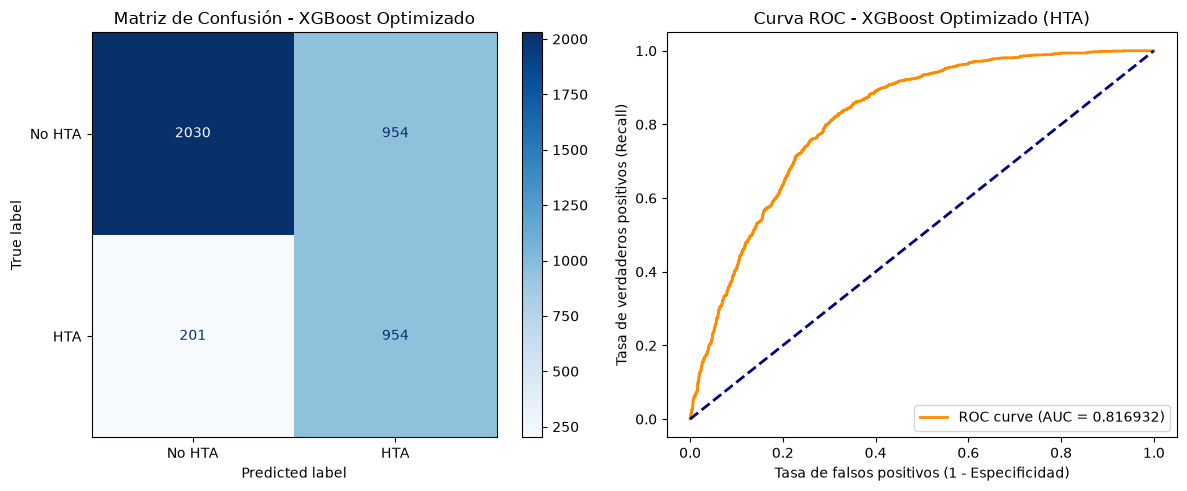

In [45]:
# ===========================================================
# EVALUACIÓN XGBOOST OPTIMIZADO - HIPERTENSIÓN
# ===========================================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_hta_opt = xgb_hta_opt.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_hta_opt = xgb_hta_opt.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_hta_opt, digits=4))

# ROC-AUC
auc_xgb_hta_opt = roc_auc_score(y_test_hta, y_pred_proba_xgb_hta_opt)
print(f"ROC-AUC Score: {auc_xgb_hta_opt:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_hta_opt = confusion_matrix(y_test_hta, y_pred_xgb_hta_opt)
disp_xgb_hta_opt = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_hta_opt, display_labels=["No HTA", "HTA"])
disp_xgb_hta_opt.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost Optimizado")

# Curva ROC
fpr_xgb_hta_opt, tpr_xgb_hta_opt, _ = roc_curve(y_test_hta, y_pred_proba_xgb_hta_opt)
axes[1].plot(fpr_xgb_hta_opt, tpr_xgb_hta_opt, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_hta_opt:.6f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost Optimizado (HTA)")
axes[1].legend(loc="lower right")

plt.savefig("../reports/figures/results/xgb_hta_optimizado.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [46]:
from sklearn.metrics import recall_score, roc_auc_score

recall_train = recall_score(y_train_hta, xgb_hta_opt.predict(X_train_hta))
recall_test = recall_score(y_test_hta, xgb_hta_opt.predict(X_test_hta))

print(f"Recall train: {recall_train:.4f} | Recall test: {recall_test:.4f}")
print(f"Diferencia: {abs(recall_train - recall_test):.4f}")

Recall train: 0.8225 | Recall test: 0.8260
Diferencia: 0.0035


In [47]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

y_proba_opt = xgb_hta_opt.predict_proba(X_test_hta)[:, 1]
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
evaluacion_umbrales = []

for u in umbrales:
    y_pred_u = (y_proba_opt >= u).astype(int)

    # Extraer directamente la matriz de confusión
    tn, fp, fn, tp = confusion_matrix(y_test_hta, y_pred_u).ravel()
    report = classification_report(y_test_hta, y_pred_u, output_dict=True)

    evaluacion_umbrales.append(
        {
            "Umbral": u,
            "Recall (Sensibilidad)": round(report["1"]["recall"], 4),
            "Precisión": round(report["1"]["precision"], 4),
            "F1-Score": round(report["1"]["f1-score"], 4),
            "Falsos Negativos (FN)": int(fn),
            "Falsos Positivos (FP)": int(fp),
        }
    )

df_umbrales_corregido = pd.DataFrame(evaluacion_umbrales)
display(df_umbrales_corregido)

,Umbral,Recall (Sensibilidad),Precisión,F1-Score,Falsos Negativos (FN),Falsos Positivos (FP)
0,0.20,0.9619,0.3876,0.5526,44,1755
1,0.25,0.9394,0.4090,0.5699,70,1568
2,0.30,0.9247,0.4241,0.5815,87,1450
3,0.35,0.9177,0.4407,0.5955,95,1345
4,0.40,0.8909,0.4621,0.6085,126,1198
5,0.45,0.8571,0.4848,0.6193,165,1052
6,0.50,0.8260,0.5000,0.6229,201,954


En cribado de salud (screening), el Índice de Youden (J = Sensibilidad + Especificidad - 1) busca el punto geométrico de máxima separación entre enfermos y sanos en la curva ROC.

In [48]:
import numpy as np
from sklearn.metrics import roc_curve

# Calcular FPR, TPR y umbrales de la curva ROC
fpr, tpr, thresholds = roc_curve(y_test_hta, y_proba_opt)

# Índice de Youden: J = Sensibilidad - FPR (ya que FPR = 1 - Especificidad)
j_scores = tpr - fpr
opt_idx = np.argmax(j_scores)
opt_threshold = thresholds[opt_idx]

print(f"El umbral óptimo según el Índice de Youden es: {opt_threshold:.2f}")

El umbral óptimo según el Índice de Youden es: 0.50


# EVALUACIÓN POR MODELO

In [49]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

#  Función de coloración
def colorear_metricas(val, metrica):
    if pd.isna(val):
        return ''
    
    if metrica == 'ROC-AUC Test':
        if val < 0.60: return 'background-color: #f8d7da; color: #721c24;'
        elif val < 0.70: return 'background-color: #ffeba8; color: #856404;'
        elif val < 0.80: return 'background-color: #d4edda; color: #155724;'
        else: return 'background-color: #28a745; color: white;'

    elif metrica == 'Recall Test':
        if val >= 0.80: return 'background-color: #28a745; color: white;'
        elif val >= 0.60: return 'background-color: #d4edda; color: #155724;'
        else: return 'background-color: #f8d7da; color: #721c24;'

    elif metrica == 'Precision Test':
        if val < 0.20: return 'background-color: #f8d7da; color: #721c24;'
        return ''

    elif metrica == 'F1-Score Test':
        if val < 0.50: return 'background-color: #f8d7da; color: #721c24;'
        elif val <= 0.65: return 'background-color: #ffeba8; color: #856404;'
        else: return 'background-color: #d4edda; color: #155724;'

    elif metrica == 'Dif. Recall (Train - Test)':
        mag = abs(val)
        if mag > 0.10: return 'background-color: #f8d7da; color: #721c24;'
        elif mag >= 0.05: return 'background-color: #ffeba8; color: #856404;'
        else: return 'background-color: #d4edda; color: #155724;'

    return ''

# 2. Función reutilizable para generar y estilizar la tabla
def generar_tabla_comparativa(diccionario_modelos, X_train, y_train, X_test, y_test):
    resultados = []

    for nombre, modelo in diccionario_modelos.items():
        y_pred_train = modelo.predict(X_train)
        y_pred_test = modelo.predict(X_test)
        y_proba_test = modelo.predict_proba(X_test)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(X_test)
        
        acc_test = accuracy_score(y_test, y_pred_test)
        recall_train = recall_score(y_train, y_pred_train)
        recall_test = recall_score(y_test, y_pred_test)
        diff_recall = recall_train - recall_test 
        
        resultados.append({
            'Modelo': nombre,
            'Accuracy Test': round(acc_test, 4),
            'Recall Test': round(recall_test, 4),
            'Dif. Recall (Train - Test)': round(diff_recall, 4),
            'Precision Test': round(precision_score(y_test, y_pred_test), 4),
            'F1-Score Test': round(f1_score(y_test, y_pred_test), 4),
            'ROC-AUC Test': round(roc_auc_score(y_test, y_proba_test), 4)
        })

    df = pd.DataFrame(resultados).sort_values(by='ROC-AUC Test', ascending=False).reset_index(drop=True)

    styler = df.style.format({
        'Accuracy Test': '{:.4f}',
        'Recall Test': '{:.4f}',
        'Dif. Recall (Train - Test)': '{:.4f}',
        'Precision Test': '{:.4f}',
        'F1-Score Test': '{:.4f}',
        'ROC-AUC Test': '{:.4f}'
    })

    for col in df.columns:
        if col != 'Modelo':
            styler = styler.map(lambda v, c=col: colorear_metricas(v, c), subset=[col])

    return styler

In [50]:
import os
import dataframe_image as dfi

# 1. Definir los modelos
modelos_rl_hta = {
    'Regresión Logística (Class Weight)': reg_log_hta_class_weight,
    'Regresión Logística (Class Weight + Sample Weight)': reg_log_hta,
    'Regresión Logística (SMOTE)': reg_log_hta_smote
}

# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(modelos_rl_hta, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_regresion_logistica.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Regresión Logística (Class Weight),0.7362,0.7758,0.0058,0.5182,0.6214,0.8163
1,Regresión Logística (SMOTE),0.7374,0.7610,0.0127,0.5201,0.6179,0.8150
2,Regresión Logística (Class Weight + Sample Weight),0.7081,0.8364,0.0013,0.4866,0.6153,0.8139


In [51]:
modelos_rf_hta = {
    'Random Forest (Class Weight)': rf_hta_class_weight,
    'Random Forest (Class Weight + Sample Weight)': rf_hta,
    'Random Forest (SMOTE)': rf_smote_hta,
    'Random Forest c/ pesos dinámicos': rf_subsample_hta,
    'Balanced Random Forest': brf_hta,
    'Balanced Random Forest (Sample Weight)': brf_hta_sample_weight,
    'Balanced Random Forest Optimizado': brf_opt_gridsearch
    }

# Generar la tabla coloreada reutilizando la función
tabla_estilizada = generar_tabla_comparativa(modelos_rf_hta, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_random_forest.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,Balanced Random Forest,0.7495,0.7229,0.2771,0.5380,0.6169,0.8161
1,Balanced Random Forest (Sample Weight),0.7183,0.8260,0.0744,0.4971,0.6207,0.8150
2,Random Forest (SMOTE),0.7652,0.4494,0.0977,0.6070,0.5164,0.8146
3,Random Forest c/ pesos dinámicos,0.7408,0.7671,0.0915,0.5243,0.6228,0.8143
4,Random Forest (Class Weight),0.7572,0.6511,0.3489,0.5554,0.5994,0.8131
5,Random Forest (Class Weight + Sample Weight),0.7514,0.6944,0.2961,0.5426,0.6092,0.8128
6,Balanced Random Forest Optimizado,0.7028,0.8199,-0.0020,0.4810,0.6063,0.8064


In [52]:
modelos_svm_hta = {
    'SVM (Class Weight)': svm_hta_cw,
    'SVM (Class Weight + Sample Weight)': svm_hta,
    'SVM (SMOTE)': svm_hta_smote,
    'SVM Optimizado': svm_hta_opt
}

tabla_estilizada = generar_tabla_comparativa(modelos_svm_hta, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_svm.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,SVM Optimizado,0.7205,0.8087,0.0249,0.4995,0.6175,0.8152
1,SVM (Class Weight),0.7238,0.7931,0.1058,0.5033,0.6158,0.8063
2,SVM (Class Weight + Sample Weight),0.7253,0.7524,0.1216,0.5052,0.6045,0.8029
3,SVM (SMOTE),0.7637,0.5255,0.1525,0.5853,0.5538,0.8000


In [53]:
modelos_xgb_hta ={
    'XGBoost (Class Weight)': xgb_model_cw_hta,
    'XGBoost (Class Weight + Sample Weight)': xgb_model_hta,
    'XGBoost (SMOTE)': xgb_model_smote_hta,
    'XGBoost Optimizado': xgb_hta_opt
}


# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(modelos_xgb_hta, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'comparativa_xgboost.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,XGBoost Optimizado,0.7209,0.8260,-0.0035,0.5000,0.6229,0.8169
1,XGBoost (SMOTE),0.7683,0.5394,0.0768,0.5933,0.5651,0.8152
2,XGBoost (Class Weight),0.7280,0.7784,0.1021,0.5082,0.6149,0.8121
3,XGBoost (Class Weight + Sample Weight),0.7321,0.7567,0.1082,0.5135,0.6118,0.8062


# TABLA COMPARATIVA DE MEJORES RESULTADOS POR MODELO

In [54]:
tabla_comparativa_final = {
    'Regresión Logística (Class Weight + Sample Weight)': reg_log_hta,
    'Balanced Random Forest Optimizado': brf_opt_gridsearch,
    'SVM Optimizado': svm_hta_opt,
    'XGBoost Optimizado': xgb_hta_opt
}

# 2. Generar y guardar la tabla en una variable
tabla_estilizada = generar_tabla_comparativa(tabla_comparativa_final, X_train_hta, y_train_hta, X_test_hta, y_test_hta)

# 3. Guardar tabla como imagen 
ruta_carpeta = '../reports/figures/results'

dfi.export(
    tabla_estilizada, 
    os.path.join(ruta_carpeta, 'tabla_comparativa_final.png'),
    table_conversion="matplotlib")

# 4. Mostrar en la pantalla del Notebook
display(tabla_estilizada)

,Modelo,Accuracy Test,Recall Test,Dif. Recall (Train - Test),Precision Test,F1-Score Test,ROC-AUC Test
0,XGBoost Optimizado,0.7209,0.8260,-0.0035,0.5000,0.6229,0.8169
1,SVM Optimizado,0.7205,0.8087,0.0249,0.4995,0.6175,0.8152
2,Regresión Logística (Class Weight + Sample Weight),0.7081,0.8364,0.0013,0.4866,0.6153,0.8139
3,Balanced Random Forest Optimizado,0.7028,0.8199,-0.0020,0.4810,0.6063,0.8064
